In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.optim import Adam
from torch.utils.data import DataLoader

from datasets.coin_detection_dataset import CoinDetectionDataset
from datasets.preprocessing import prepare_dataset
from models.difference_regressor import DifferenceRegressor

device = torch.device("mps")

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

In [ ]:
train_ds = CoinDetectionDataset(
    PROJECT_ROOT / "data/raw/train.pkl"
)
val_ds = CoinDetectionDataset(
    PROJECT_ROOT / "data/raw/val.pkl"
)
config = {
    "offset": 15,
    "bg_percent": 0.0,
    "iou_threshold": 0.3,
}
reg_train_ds = prepare_dataset(train_ds, config, num_of_crops_per_image=64)

reg_val_ds = prepare_dataset(val_ds, config, num_of_crops_per_image=64)

train_loader = DataLoader(reg_train_ds, batch_size=32, shuffle=True)

val_loader = DataLoader(reg_val_ds, batch_size=32)

In [3]:
model = DifferenceRegressor().to(device)

criterion = nn.MSELoss()

optimizer = Adam(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4,
)

epochs = 15

train_losses = []
val_losses = []

best_val_loss = float("inf")

In [ ]:
for epoch in range(epochs):
    model.train()

    train_loss_sum = 0
    train_batches = 0

    for crops, labels, bb_diffs in train_loader:
        mask = labels != 9

        if not mask.any():
            continue
        crops = crops[mask].to(device)
        targets = bb_diffs[mask].to(device)

        optimizer.zero_grad()
        predictions = model(crops)
        loss = criterion(predictions, targets)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item()
        train_batches += 1

    train_loss = train_loss_sum / train_batches

    model.eval()

    val_loss_sum = 0
    val_batches = 0

    with torch.no_grad():
        for crops, labels, bb_diffs in val_loader:
            mask = labels != 9

            if not mask.any():
                continue

            crops = crops[mask].to(device)
            targets = bb_diffs[mask].to(device)

            predictions = model(crops)
            loss = criterion(predictions, targets)

            val_loss_sum += loss.item()
            val_batches += 1
    val_loss = val_loss_sum / val_batches

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{epochs}"
        f"Train MSE: {train_loss:.4f}"
        f"Val MSE: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            CHECKPOINT_DIR / "regressor_best.pth",
        )

Epoch 1/15 | Train MSE: 50.4435 | Val MSE: 30.3019
Epoch 2/15 | Train MSE: 16.4901 | Val MSE: 20.1251
Epoch 3/15 | Train MSE: 9.6800 | Val MSE: 12.7339
Epoch 4/15 | Train MSE: 6.5357 | Val MSE: 9.9606
Epoch 5/15 | Train MSE: 4.9464 | Val MSE: 9.6066
Epoch 6/15 | Train MSE: 4.4979 | Val MSE: 10.1429
Epoch 7/15 | Train MSE: 4.3391 | Val MSE: 9.1390
Epoch 8/15 | Train MSE: 3.8582 | Val MSE: 8.3576
Epoch 9/15 | Train MSE: 3.5641 | Val MSE: 8.6911
Epoch 10/15 | Train MSE: 3.4773 | Val MSE: 9.0791
Epoch 11/15 | Train MSE: 3.4043 | Val MSE: 8.0659
Epoch 12/15 | Train MSE: 2.9987 | Val MSE: 7.5081
Epoch 13/15 | Train MSE: 3.0939 | Val MSE: 7.7696
Epoch 14/15 | Train MSE: 2.8969 | Val MSE: 7.5738
Epoch 15/15 | Train MSE: 2.9249 | Val MSE: 6.7417


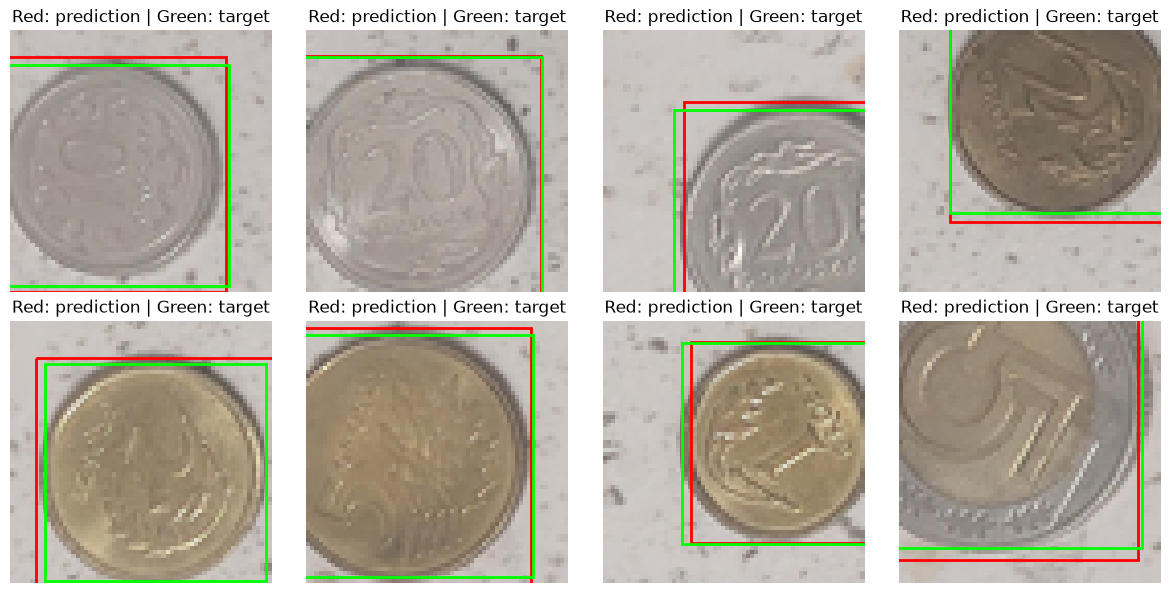

In [ ]:
model.load_state_dict(torch.load(CHECKPOINT_DIR / "regressor_best.pth", map_location=device))
model.eval()

crops, labels, bb_diffs = next(iter(val_loader))
mask = labels != 9
crops = crops[mask][:8]
targets = bb_diffs[mask][:8]
with torch.no_grad():
    predictions = model(crops.to(device)).cpu()
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    predicted_box = [predictions[i, 0], predictions[i, 1], 64 + predictions[i, 2], 64 + predictions[i, 3]]
    target_box = [targets[i, 0], targets[i, 1], 64 + targets[i, 2], 64 + targets[i, 3]]

    ax.imshow(crops[i].permute(1, 2, 0))
    ax.add_patch(plt.Rectangle((predicted_box[0], predicted_box[1]), predicted_box[2] - predicted_box[0], predicted_box[3] - predicted_box[1], fill=False, edgecolor="red", linewidth=2, label="Prediction"))
    ax.add_patch(plt.Rectangle((target_box[0], target_box[1]), target_box[2] - target_box[0], target_box[3] - target_box[1], fill=False, edgecolor="lime", linewidth=2, label="Target"))
    ax.set_title("Red: prediction | Green: target")
    ax.axis("off")

plt.tight_layout()
plt.show()